# Vancouver F&B Market Analysis: Part 1, Business Licences by Neighbourhood

**Business question:** Pacific Horizons Hospitality Group (PHHG - a fictional client) wants to open a new
dining and lounge concept in Vancouver. Which neighbourhoods have room for one more F&B business?

**This notebook looks at competition:** how many restaurants, cafes and bars already operate in each
neighbourhood, how that number has changed since 2015 and since COVID, and how often F&B businesses close.

**Datasets:** City of Vancouver Open Data - I used Excel format for initial exploration, and CSV files to load and perform analysis
1. Business licences (2013-2024 and 2024-2026):
- https://opendata.vancouver.ca/explore/assets/business-licences-2013-to-2024/view
- https://opendata.vancouver.ca/explore/assets/business-licences/view
2. Local area boundaries:
- https://opendata.vancouver.ca/explore/assets/local-area-boundary/view/ 

**Steps taken**
1. Load the licence files
2. Fix two data problems: a duplicated year (2024) and renamed business categories
3. Keep only food & beverage businesses
4. Assign each business to a neighbourhood using its coordinates
5. Build one summary table (one row per neighbourhood)
6. Visualize and interpret

## 1. Load the data

I only loaded the columns I need. Each licence file is about 200 MB, so loading only 10 of the 25 columns
saves a lot of memory and time.

Initially I got business license data from the following periods: 1996-2012, 2013-2024, and 2024-2026. I start in 2013 rather than 1996: the 1996–2012 file only has coordinates for about half its rows,
which would make neighbourhood counts from those years unreliable. 

Ten-plus years (2013-2026) is
enough to see long-term and post-COVID trends.

In [65]:
# logistics
import json                       # to read the neighbourhood shapes which are stored as JSON text
import numpy as np                # maths on whole columns at once
import pandas as pd               # tables aka dataframes
import matplotlib.pyplot as plt   # charts
from matplotlib.path import Path  # point-in-polygon test: "is this point inside this shape?"

import os                         # for creating folders

RAW = "../data/raw/"              # to access the raw csv files
os.makedirs("../data/processed", exist_ok=True)   # make sure output folders exist
os.makedirs("../images", exist_ok=True)           # (exist_ok=True: no error if they already do)

def load(filename, columns=None):
    # read one csv file with the same settings every time
    return pd.read_csv(
        RAW + filename,
        sep=";",               # these files have semicolons as separators
        dtype=str,             # read everything as text so "00" or postal codes are not altered
        encoding="utf-8-sig",  # take away the invisible marker at the strat of the file
        usecols=columns,       # only these columns (None = all)
    )

licence_cols = ["FOLDERYEAR", "LicenceNumber", "LicenceRevisionNumber", "BusinessName",
                "BusinessTradeName", "Status", "BusinessType", "BusinessSubType",
                "LocalArea", "geo_point_2d"]

lic_13 = load("business-licences-2013-2024.csv", licence_cols)
lic_24 = load("business-licences-2024-2026.csv", licence_cols)

print(f"2013-2024 file: {len(lic_13):,} rows")
print(f"2024-2026 file: {len(lic_24):,} rows")

2013-2024 file: 782,330 rows
2024-2026 file: 206,352 rows


## 2. Fix the duplicated year

`FOLDERYEAR` is the licence year as two digits ("13" = 2013). Every licence expires on Dec 31 of that year,
so one row = one business's license for one year.

**Problem I found:** licence year 2024 appears in *both* files. The same ~57,000 licence numbers show up in each,
because the City exported the two files at different times (2025 and 2026).
If I stack them as is, every 2024 business is counted twice.

**What I did** keep 2024 only from the newer file (it is the more recent snapshot and uses the current category names).

In [66]:
# check the problem first: how many licence numbers from 2024 appear in both files?
in_old = set(lic_13.loc[lic_13["FOLDERYEAR"] == "24", "LicenceNumber"])
in_new = set(lic_24.loc[lic_24["FOLDERYEAR"] == "24", "LicenceNumber"])
print(f"2024 licence numbers found in BOTH files: {len(in_old & in_new):,}")   # & = overlap of two sets

# fix: drop 2024 from the older file, then stack the two files on top of each other
lic_13 = lic_13[lic_13["FOLDERYEAR"] != "24"]
lic = pd.concat([lic_13, lic_24], ignore_index=True)

# turn the two-digit year into a real number: "13" -> 2013
lic["year"] = 2000 + lic["FOLDERYEAR"].astype(int)

# check the fix: each year should now appear once, 2013 to 2026
lic["year"].value_counts().sort_index()

2024 licence numbers found in BOTH files: 56,952


year
2013    60914
2014    60580
2015    60937
2016    61394
2017    60060
2018    66177
2019    70773
2020    69300
2021    68389
2022    68423
2023    69793
2024    62979
2025    69890
2026    73483
Name: count, dtype: int64

## 3. Keep only food & beverage businesses

**Problem I found:** the City renamed its business categories in 2024. For example, before 2024 restaurants are
`Restaurant Class 1 *Historic*`; from 2024 they are just `Restaurant`. A filter on one name would lose every year that uses the other name.

**My F&B definition** (places where people sit down or grab food/drinks - aka the client's competitors):

| Before 2024 | From 2024 |
|---|---|
| Restaurant Class 1 / Class 2 | Restaurant |
| Ltd Service Food Establishment (cafes, takeout, food courts) | Limited Service Food Establishment |
| Liquor Establishment Standard / Extended (bars, pubs, lounges) | Liquor Establishment |

**Excluded on purpose:** caterers (no storefront), grocery/food retail, food manufacturers and wholesalers, since they are not competing for the same diners.

In [67]:
fnb_types = [
    # old names (up to 2023)
    "Restaurant Class 1 *Historic*",
    "Restaurant Class 2 *Historic*",
    "Ltd Service Food Establishment *Historic*",
    "Liquor Establishment Standard *Historic*",
    "Liquor Establishment Extended  *Historic*",   # note: the City's data has TWO spaces before *Historic* -- found out from excel file format

    # new names (2024 onwards)
    "Restaurant",
    "Limited Service Food Establishment",
    "Liquor Establishment",
]

# .isin() keeps rows whose BusinessType is in our list
#   .copy() makes fnb its own table, not a view of lic
fnb = lic[lic["BusinessType"].isin(fnb_types)].copy()

# a licence can have several revisions in the same year (e.g. an address change)
# keep only the latest revision so each business is counted once per year
fnb = (fnb.sort_values("LicenceRevisionNumber")
          .drop_duplicates(subset=["year", "LicenceNumber"], keep="last"))

print(f"F&B licence-years: {len(fnb):,}")
fnb["Status"].value_counts()

F&B licence-years: 53,639


Status
Issued                  44868
Gone Out of Business     5068
Pending                  2365
Cancelled                1133
Inactive                  205
Name: count, dtype: int64

**What `Status` means for this analysis:**
- `Issued` = the business was licensed and operating that year --> this is what I count as "active".
- `Gone Out of Business` = it closed during that year --> used for the closure rate (is the area booming/shrinking?).
- `Pending`, `Cancelled`, `Inactive` = never opened or not operating --> excluded.

## 4. Assign each business to a neighborhood

**Problem I found:** the `LocalArea` (neighborhood) column is completely empty in the 2013-2024 file.
But `geo_point_2d` (latitude, longitude) is filled in for 93-98% of active F&B licences.

**What I did** the City's `local-area-boundary` file has the outline (polygon) of each of the 22 neighborhoods.
For every business, I test which outline its point falls inside. This is a point-in-polygon test.
I use the same method for every year, including 2024-2026, so all years are treated consistently.

In [68]:
# split "49.26, -123.11" into two number columns
coords = fnb["geo_point_2d"].str.split(",", expand=True).astype(float)
fnb["lat"] = coords[0]
fnb["lon"] = coords[1]

boundary = load("local-area-boundary.csv")

fnb["neighbourhood"] = None # start empty and fill in one neighborhood at a time
area_km2 = {} # we'll also measure each neighborhood's size

for _, row in boundary.iterrows(): # one row = one neighbourhood
    outline = np.array(json.loads(row["Geom"])["coordinates"][0]) # list of (lon, lat) corners
    shape = Path(outline)

    todo = fnb["lat"].notna() & fnb["neighbourhood"].isna()  # points not yet assigned
    inside = shape.contains_points(fnb.loc[todo, ["lon", "lat"]].values)
    fnb.loc[todo[todo].index[inside], "neighbourhood"] = row["Name"]

    # area in km2: convert degrees to km (1 degree of latitude ~ 110.57 km, longitude shrinks with cos(latitude)),
    # then use the "shoelace formula" for the area of a polygon.
    x = outline[:, 0] * 111.32 * np.cos(np.radians(49.25))
    y = outline[:, 1] * 110.57
    area_km2[row["Name"]] = 0.5 * abs(np.dot(x, np.roll(y, 1)) - np.dot(y, np.roll(x, 1)))

active = fnb[fnb["Status"] == "Issued"]
print(f"Active F&B licences matched to a neighbourhood: {active['neighbourhood'].notna().mean():.1%}")
print(f"Total area of the 22 neighbourhoods: {sum(area_km2.values()):.0f} km2 (City of Vancouver is ~115 km2)")

Active F&B licences matched to a neighbourhood: 95.7%
Total area of the 22 neighbourhoods: 118 km2 (City of Vancouver is ~115 km2)


The area check matters: if my km² maths were wrong, the total would not be close to the city's official
land area (115 km²). Being close tells me the density numbers later can be trusted.

## 5. Build the neighbourhood summary table

one row per neighborhood, one column per question:

| Column | Question it answers |
|---|---|
| `fnb_2025` | How much competition is there today? (2025 = latest complete year) |
| `per_km2` | How crowded is it? (businesses per km²) |
| `growth_10yr_pct` | Long-term trend: 2015 --> 2025 |
| `growth_post_covid_pct` | Recovery: 2019 (pre-COVID) --> 2025 |
| `closure_rate_pct` | How often do F&B businesses close here? (2022-2025) |

In [69]:
# count active f&b businesses per neighbourhood per year
# groupby = "for each (neighbourhood, year) pair", size() = "count the rows"
# unstack() turns years into columns, like a pivot table in excel
counts = active.groupby(["neighbourhood", "year"]).size().unstack(fill_value=0)

summary = pd.DataFrame({
    "fnb_2015": counts[2015],
    "fnb_2019": counts[2019],
    "fnb_2025": counts[2025],
})
summary["km2"] = pd.Series(area_km2)
summary["per_km2"] = summary["fnb_2025"] / summary["km2"]
summary["growth_10yr_pct"] = (summary["fnb_2025"] / summary["fnb_2015"] - 1) * 100
summary["growth_post_covid_pct"] = (summary["fnb_2025"] / summary["fnb_2019"] - 1) * 100

# closure rate: of the businesses that were operating or closed in 2022-2025, what share closed?
recent = fnb[fnb["year"].between(2022, 2025) & fnb["Status"].isin(["Issued", "Gone Out of Business"])]
summary["closure_rate_pct"] = (recent.groupby("neighbourhood")["Status"]
                                     .apply(lambda s: (s == "Gone Out of Business").mean() * 100))

summary = summary.round(1).sort_values("fnb_2025", ascending=False)
summary.to_csv("../data/processed/fnb_by_neighbourhood.csv")   # save the result for later notebooks
summary

,fnb_2015,fnb_2019,fnb_2025,km2,per_km2,growth_10yr_pct,growth_post_covid_pct,closure_rate_pct
neighbourhood,,,,,,,,
Downtown,944,951,898,4.6,193.3,-4.9,-5.6,9.5
West End,303,297,297,2.2,132.5,-2.0,0.0,10.9
Kitsilano,257,243,253,6.3,40.0,-1.6,4.1,8.0
Mount Pleasant,185,218,212,3.7,57.4,14.6,-2.8,10.5
Fairview,236,252,196,3.6,54.3,-16.9,-22.2,10.7
Grandview-Woodland,161,175,186,4.7,39.4,15.5,6.3,8.9
Kensington-Cedar Cottage,145,162,162,7.2,22.5,11.7,0.0,8.1
Riley Park,115,118,120,4.9,24.5,4.3,1.7,8.4
Renfrew-Collingwood,97,100,116,8.0,14.4,19.6,16.0,9.0


In [70]:
# city-wide trend: how many active f&b businesses each year?
citywide = active.groupby("year").size()
citywide

year
2013    3115
2014    3163
2015    3212
2016    3249
2017    3273
2018    3280
2019    3249
2020    3137
2021    3113
2022    3133
2023    3168
2024    3258
2025    3227
2026    3291
dtype: int64

## 6. Visualize the trend and business density

### Chart 1: City-wide trend (a line chart)

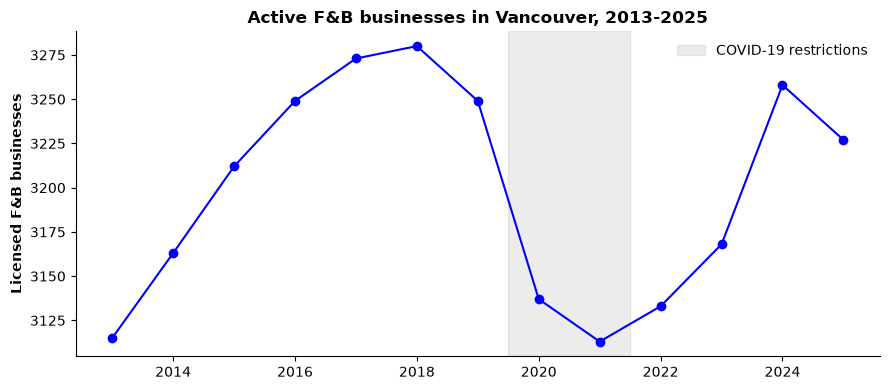

In [ ]:
# create an empty chart
    # fig = the whole image, ax = the drawing area inside it ("axes")
    # figsize=(wide,tall) in inches
fig, ax = plt.subplots(figsize=(9,4))

# a list of counts with years as labels
    # loc[2013:2025] keeps 2013-2025
    # 2026 is left out because the year isn't over yet
    # marker="o" puts a dot on each year
citywide.loc[2013:2025].plot(ax=ax, marker="o", color="blue")

# shade the covid years grey so it's clear why the trend line dips
    # axvspan = "vertical span": a shaded area from halfway of 2019-2020 to halfway 2021-2022 (covers the 2020 and 2021 dots)
    # alpha=0.15 to makes it see-thru
ax.axvspan(2019.5, 2021.5, color="grey", alpha=0.15, label="COVID-19 restrictions")

# decorations
ax.set_title("Active F&B businesses in Vancouver, 2013-2025", weight='bold')
ax.set_xlabel("")
ax.set_ylabel("Licensed F&B businesses", weight='bold')
ax.legend(frameon=False) # i dont want a box framing the label
ax.spines[["top", "right"]].set_visible(False) # for a cleaner look

plt.tight_layout() # stop labels from getting cut off in the saved image
plt.savefig("../images/citywide_trend.png", dpi=150) # save as an image file, dpi for sharpnesss
plt.show() # display it here

### Chart 2: Opportunity map (scatter/bubble chart)
Each bubble is one neighborhood.
- x-axis: density -- how crowded it is (F&B businesses per km2)
- y-axis: growth since covid -- how much F&B has grown since 2019
- bubble size: number of F&B businesses it has today

Interesting spots are top-left: growing, but not crowded yet.

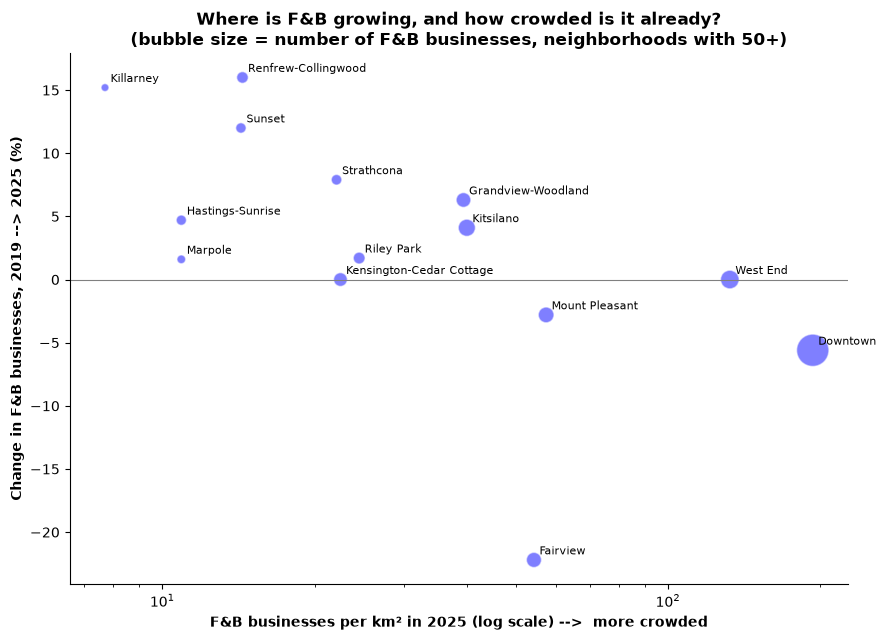

In [72]:
# only keep neighborhoods with at least 50 f&b businesses
    # with very small numbers, percentages jump around a lot (going from 10 to 15 businesses is already +50%), which would be misleading
s = summary[summary["fnb_2025"] >= 50]   # leave out very small markets

fig, ax = plt.subplots(figsize=(9, 6.5))

# ax.scatter(x values, y values,..) draws one dot per row
# s= sets the bubble Sizes: fnb_2025 * 0.6 shrinks them so Downtown's bubble doesn't cover everything
# alpha=0.5 = half see-through so overlapping bubbles stay visible
ax.scatter(s["per_km2"], s["growth_post_covid_pct"], s=s["fnb_2025"] * 0.6,
           alpha=0.5, color="blue", edgecolor="white")

# write each neighborhood's name next to its bubble
    # .iterrows() goes through the table 1 row at a time: name = row label (the neighborhood), r = that row's values.
for name, r in s.iterrows():
    ax.annotate(name,                                        # text to write
                (r["per_km2"], r["growth_post_covid_pct"]),  # point it belongs to
                xytext=(4, 4), textcoords="offset points",   # nudge the text 4 points right and up, off the bubble
                fontsize=8)

# a horizontal line at 0%: bubbles above it grew since 2019, bubbles below it shrank
ax.axhline(0, color="grey", lw=0.8)

# log scale on the x-axis: each step to the right is 10x more (1, 10, 100) instead of +1
    # without it, dense Downtown (193 per km2) sits far to the right and every other neighbourhood gets squashed together on the left
ax.set_xscale("log")    

# decor
ax.set_xlabel("F&B businesses per km² in 2025 (log scale) -->  more crowded", weight='bold')
ax.set_ylabel("Change in F&B businesses, 2019 --> 2025 (%)", weight='bold')
ax.set_title("Where is F&B growing, and how crowded is it already?\n(bubble size = number of F&B businesses, neighborhoods with 50+)", weight='bold')
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("../images/opportunity_map.png", dpi=150)
plt.show()

## 7. Early findings

1. **Vancouver lost restaurants during Covid and has almost recovered.** The number of active F&B businesses
   went from 3280 in 2018 down to 3113 in 2021 (about 5% fewer), then back up to 3227 in 2025.
   Note: the chart's y-axis doesnt start at 0 so the ups and downs look bigger than they are.

2. **Downtown is already very crowded, and it's shrinking.** It has the most F&B businesses (898) and the most per km2 (about 193),
   but it has 5.6% fewer than in 2019. This matches the client's worry that Downtown is too competitive.
3. **Mount Pleasant grew a lot before Covid, but not since.** It went up 18% from 2015 to 2019, then down 3% by 2025.
   It's already fairly crowded (about 57 per km2).
4. **Grandview-Woodland and Strathcona are growing steadily without being crowded.** Both grew over the last 10 years
   (+16% and +26%) and since Covid (+6% and +8%). Downtown has about 5 to 9 times more F&B businesses per km2 than they do,
   and their closure rates are about average (8.9%).
   Based on competition alone, these are my two **early picks**.
5. **The fastest growth is in East Vancouver neighbourhoods further from downtown** (Renfrew-Collingwood +16%, Killarney +15%,
   Sunset +12% since 2019), but they started with only a few F&B businesses. This could mean either there are customers
   who aren't being served yet, or just simply fewer customers go there. I need data on customer activity to know which.
6. **Two neighbourhoods dropped sharply and I want to understand why before drawing conclusions:** Fairview (-22% since 2019)
   and Oakridge (-58%). My guesses are the big construction project on Broadway (Fairview) and Oakridge Centre mall being rebuilt.

## Limitations
- **This only looks at competition.** It counts F&B businesses, but doesn't yet measure how many customers
  are around (how busy the streets are, new constructions, etc.).
- **A licence isn't proof a business is open.** Some businesses may only operate for a short time, counting
  `Issued` licences is the best sign of "open" that this data has.
- **Some active licences have no coordinates** and are left out of neighbourhood counts.
- **Category names changed in 2024.** I matched old names to new ones. The city-wide count doesn't suddenly jump
  between 2023 and 2024 in Chart 1, which suggests the matching works.

## Next steps
1. Add parking tickets (2011–2026) as a rough measure of how busy each area is, matched to neighbourhoods by street and block.
2. Add building permits to see where new construction is happening.
3. Combine competition and customer activity into one score and recommend the top two neighbourhoods for PHHG.